# Klasifikasi Citra Fashion-MNIST dengan CNN Sederhana

## 1. Dataset dari Kaggle

Dataset yang digunakan adalah [Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist) dari Kaggle. Dataset ini berisi citra grayscale berukuran 28x28 piksel dari 10 kategori pakaian. Setiap citra memiliki satu label kelas, sehingga sesuai untuk kasus **image classification** multiclass.

Notebook ini mengambil dataset dengan KaggleHub, membangun CNN sederhana, lalu menghitung accuracy, precision, recall, dan F1-score pada data uji.

In [1]:
# Jalankan sekali jika dependensi belum tersedia.
%pip install -q kagglehub tensorflow scikit-learn seaborn

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print("TensorFlow:", tf.__version__)
print("Jumlah kelas:", len(CLASS_NAMES))

TensorFlow: 2.21.0
Jumlah kelas: 10


## 2. Mengunduh dan menyiapkan data



In [2]:
import kagglehub

DATASET_DIR = Path(kagglehub.dataset_download("zalando-research/fashionmnist"))
csv_files = sorted(DATASET_DIR.rglob("*.csv"))
print("Lokasi dataset:", DATASET_DIR)
print("File CSV:", [file.name for file in csv_files])

if not csv_files:
    raise FileNotFoundError("File CSV Fashion-MNIST tidak ditemukan pada dataset Kaggle.")

def read_split(name: str) -> pd.DataFrame:
    candidates = [file for file in csv_files if name in file.stem.lower()]
    if not candidates:
        raise FileNotFoundError(f"File split '{name}' tidak ditemukan.")
    return pd.read_csv(candidates[0])

train_df = read_split("train")
test_df = read_split("test")
print("Ukuran train:", train_df.shape)
print("Ukuran test :", test_df.shape)
train_df.head()

C:\Users\Ilham Febriyansyah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 68.8M/68.8M [00:15<00:00, 4.67MB/s]

Extracting files...


Lokasi dataset: C:\Users\Ilham Febriyansyah\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4
File CSV: ['fashion-mnist_test.csv', 'fashion-mnist_train.csv']
Ukuran train: (60000, 785)
Ukuran test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
LABEL_COLUMN = "label"
if LABEL_COLUMN not in train_df.columns or LABEL_COLUMN not in test_df.columns:
    raise KeyError("Kolom label tidak ditemukan pada CSV Fashion-MNIST.")

pixel_columns = [column for column in train_df.columns if column != LABEL_COLUMN]
if len(pixel_columns) != 28 * 28:
    raise ValueError(f"Jumlah kolom piksel tidak sesuai: {len(pixel_columns)} (seharusnya 784).")

X = train_df[pixel_columns].to_numpy(dtype="float32") / 255.0
y = train_df[LABEL_COLUMN].to_numpy(dtype="int64")
X_test = test_df[pixel_columns].to_numpy(dtype="float32") / 255.0
y_test = test_df[LABEL_COLUMN].to_numpy(dtype="int64")

X = X.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=SEED, stratify=y
)

print(f"Train: {X_train.shape}, validasi: {X_val.shape}, test: {X_test.shape}")
print("Rentang piksel:", float(X_train.min()), "sampai", float(X_train.max()))

Train: (54000, 28, 28, 1), validasi: (6000, 28, 28, 1), test: (10000, 28, 28, 1)
Rentang piksel: 0.0 sampai 1.0


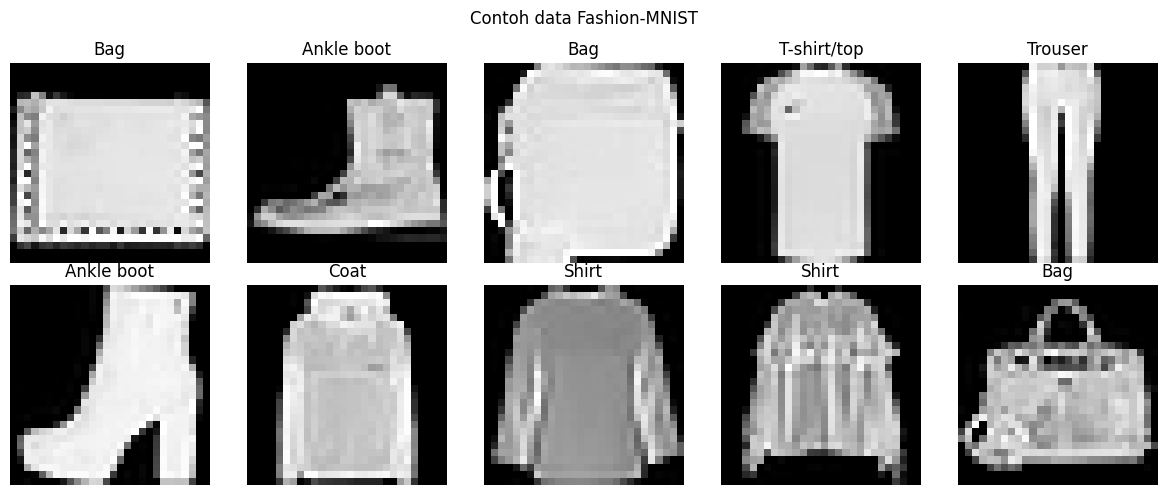

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for image, label, ax in zip(X_train[:10], y_train[:10], axes.ravel()):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.suptitle("Contoh data Fashion-MNIST")
plt.tight_layout()
plt.show()

## 3. Arsitektur deep learning sederhana

Model menggunakan dua blok `Conv2D`  `MaxPooling2D`, kemudian `Flatten`, `Dense`, `Dropout`, dan output `Softmax` untuk 10 kelas. Normalisasi piksel dilakukan sebelum training.

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 89ms/step - accuracy: 0.7745 - loss: 0.6203 - val_accuracy: 0.8475 - val_loss: 0.4130
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 85ms/step - accuracy: 0.8580 - loss: 0.3934 - val_accuracy: 0.8695 - val_loss: 0.3499
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.8770 - loss: 0.3401 - val_accuracy: 0.8845 - val_loss: 0.3226
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.8878 - loss: 0.3075 - val_accuracy: 0.8897 - val_loss: 0.2994
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 85ms/step - accuracy: 0.8964 - loss: 0.2859 - val_accuracy: 0.8940 - val_loss: 0.2822
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 86ms/step - accuracy: 0.9032 - loss: 0.2664 - val_accuracy: 0.8982 - val_loss: 0.2704
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 101ms/step - accuracy: 0.9093 - loss: 0.2469 - val_accuracy: 0.8998 - val_loss: 0.2663
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 86ms/step - accuracy: 0.9148 - loss: 0.2318 -

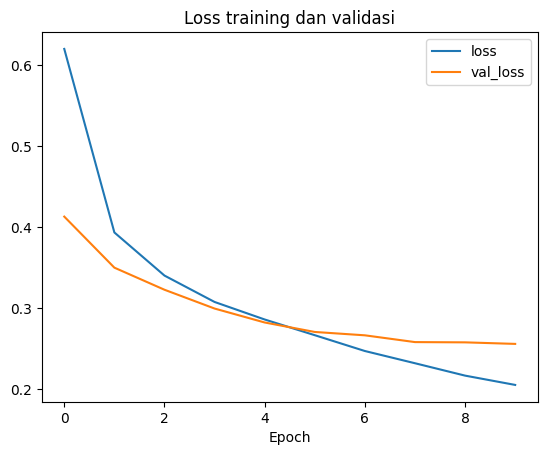

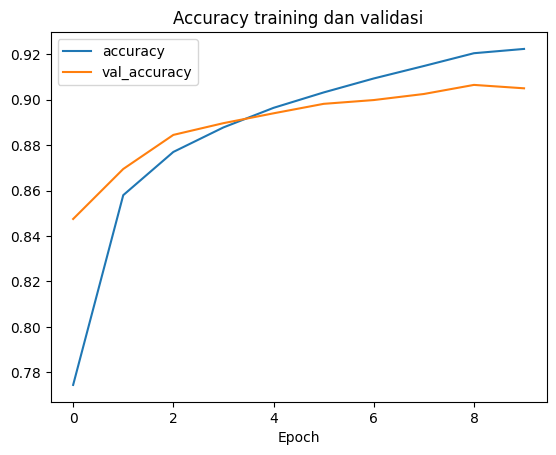

In [10]:
history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot(title="Loss training dan validasi")
plt.xlabel("Epoch")
plt.show()
history_df[["accuracy", "val_accuracy"]].plot(title="Accuracy training dan validasi")
plt.xlabel("Epoch")
plt.show()

## 4. Evaluasi model

Prediksi dievaluasi pada **data test yang tidak digunakan saat training**. `average="weighted"` digunakan untuk precision, recall, dan F1-score agar memperhitungkan jumlah sampel tiap kelas.

In [13]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
y_probability = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_probability, axis=1)

metrics_result = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
metrics_df = pd.DataFrame.from_dict(metrics_result, orient="index", columns=["Nilai"])
metrics_df["Nilai"] = metrics_df["Nilai"].map(lambda value: f"{value:.4f}")
display(metrics_df)
print(f"Test loss: {test_loss:.4f}")

,Nilai
Accuracy,0.9161
Precision (weighted),0.9193
Recall (weighted),0.9161
F1-score (weighted),0.9169


Test loss: 0.2390


              precision    recall  f1-score   support

 T-shirt/top     0.8885    0.8130    0.8491      1000
     Trouser     0.9880    0.9850    0.9865      1000
    Pullover     0.9037    0.8630    0.8829      1000
       Dress     0.9194    0.9350    0.9271      1000
        Coat     0.9058    0.8560    0.8802      1000
      Sandal     0.9918    0.9700    0.9808      1000
       Shirt     0.7073    0.8240    0.7612      1000
     Sneaker     0.9664    0.9480    0.9571      1000
         Bag     0.9831    0.9870    0.9850      1000
  Ankle boot     0.9396    0.9800    0.9594      1000

    accuracy                         0.9161     10000
   macro avg     0.9193    0.9161    0.9169     10000
weighted avg     0.9193    0.9161    0.9169     10000



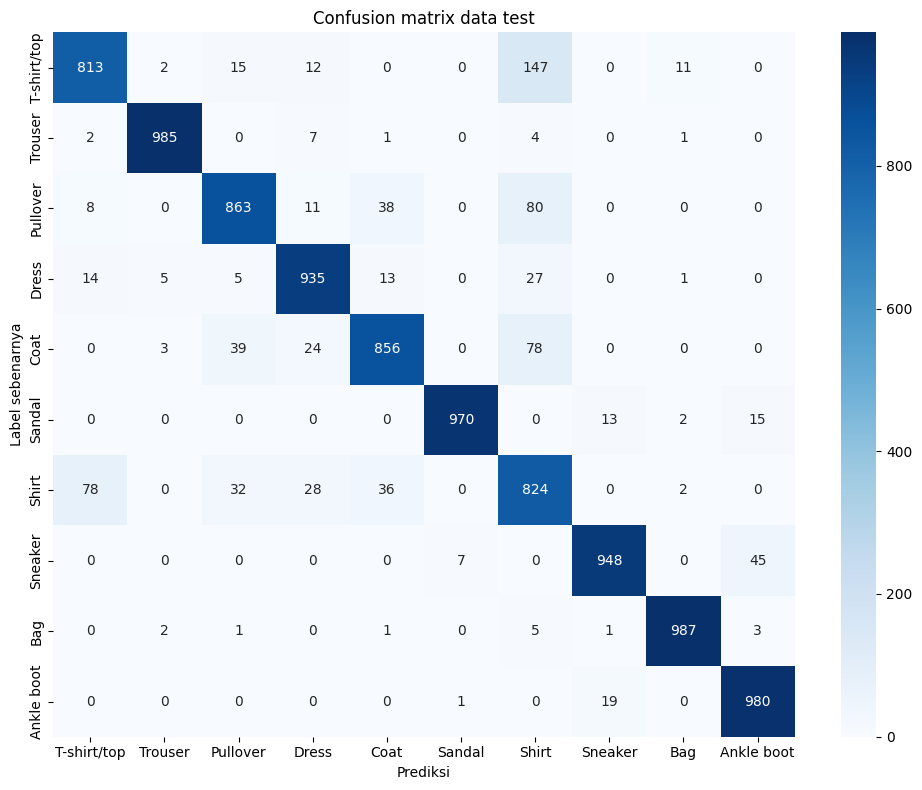

In [14]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion matrix data test")
plt.tight_layout()
plt.show()